In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!mkdir -p /content/mvtec_ad
!tar -xf "/content/drive/MyDrive/mvtec/capsule.tar.xz" -C /content/mvtec_ad
!ls /content/mvtec_ad/capsule

ground_truth  license.txt  readme.txt  test  train


In [4]:
# prepare_data.py
import cv2, random, shutil
from pathlib import Path

CATEGORY = "capsule"
SRC = Path("/content/mvtec_ad") / CATEGORY
DST = Path("/content/datasets") / CATEGORY
random.seed(42)

In [5]:
classes = sorted(p.name for p in (SRC / "test").iterdir()
                 if p.is_dir() and p.name != "good")
cls_id = {c: i for i, c in enumerate(classes)}

def mask_to_yolo(mask_path, cls):
    m = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    h, w = m.shape
    m = (m > 0).astype("uint8")
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for c in contours:
        if cv2.contourArea(c) < 20:      # drop tiny noise
            continue
        c = cv2.approxPolyDP(c, 0.002 * cv2.arcLength(c, True), True).reshape(-1, 2)
        if len(c) < 3:
            continue
        pts = " ".join(f"{x/w:.6f} {y/h:.6f}" for x, y in c)
        lines.append(f"{cls} {pts}")
    return lines

# (image_path, label_lines) for every defective image
defect = []
for c in classes:
    for img in sorted((SRC / "test" / c).glob("*.png")):
        mask = SRC / "ground_truth" / c / f"{img.stem}_mask.png"
        defect.append((img, mask_to_yolo(mask, cls_id[c])))

random.shuffle(defect)
n_val = int(0.2 * len(defect))
splits = {"val": defect[:n_val], "train": defect[n_val:]}

# Defect-free images as negatives (empty labels)
good_train = sorted((SRC / "train" / "good").glob("*.png"))[:100]
good_val = sorted((SRC / "test" / "good").glob("*.png"))
splits["train"] += [(p, []) for p in good_train]
splits["val"] += [(p, []) for p in good_val]

for split, items in splits.items():
    (DST / "images" / split).mkdir(parents=True, exist_ok=True)
    (DST / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img, lines in items:
        name = f"{img.parent.name}_{img.name}"        # avoid name clashes
        shutil.copy(img, DST / "images" / split / name)
        (DST / "labels" / split / name.replace(".png", ".txt")).write_text("\n".join(lines))

yaml = f"path: {DST.resolve()}\ntrain: images/train\nval: images/val\nnames:\n"
yaml += "".join(f"  {i}: {c}\n" for c, i in cls_id.items())
(DST / "data.yaml").write_text(yaml)
print("Classes:", classes, "| train:", len(splits["train"]), "val:", len(splits["val"]))

Classes: ['crack', 'faulty_imprint', 'poke', 'scratch', 'squeeze'] | train: 188 val: 44


(np.float64(-0.5), np.float64(999.5), np.float64(999.5), np.float64(-0.5))

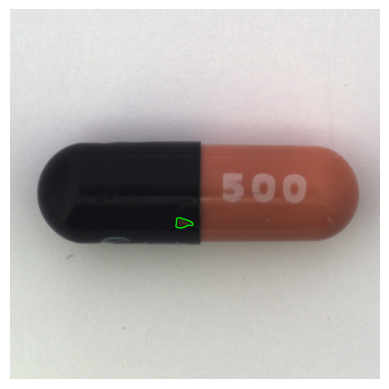

In [6]:
#Optional sanity check: to confirm the polygons line up with the defects
import matplotlib.pyplot as plt
import numpy as np

lbl = next(p for p in (DST/"labels"/"train").glob("*.txt") if p.read_text().strip())
img = cv2.imread(str(DST/"images"/"train"/lbl.name.replace(".txt", ".png")))
h, w = img.shape[:2]
for line in lbl.read_text().splitlines():
    pts = np.array(line.split()[1:], dtype=float).reshape(-1, 2) * [w, h]
    cv2.polylines(img, [pts.astype(np.int32)], True, (0, 255, 0), 2)
plt.imshow(img[..., ::-1]); plt.axis("off")

In [8]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 6.1 MB/s eta 0:00:00


In [9]:
!nvidia-smi

Tue Oct 13 14:27:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [10]:
# train.py
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")
model.train(
    data="datasets/capsule/data.yaml",
    epochs=100,
    imgsz=800,        # higher resolution helps small scratches/cracks
    batch=8,
    patience=20,      # early stopping
    hsv_v=0.4,        # brightness variation (simulates factory lighting)
    hsv_s=0.4,
    degrees=15,
    translate=0.1,
    scale=0.3,
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    project="runs", name="capsule_v8n",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets/capsule/data.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, free

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb885bc60b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,  

In [11]:
!find /content -name best.pt

/content/runs/segment/runs/capsule_v8n/weights/best.pt


In [12]:
!mkdir -p /content/drive/MyDrive/mvtec
!cp -r /content/runs /content/drive/MyDrive/mvtec/runs

In [13]:
# evaluate.py
from ultralytics import YOLO

model = YOLO("/content/runs/segment/runs/capsule_v8n/weights/best.pt")  # use your actual path
m = model.val(data="/content/datasets/capsule/data.yaml", imgsz=800)

print("Mask mAP50    :", m.seg.map50)
print("Mask mAP50-95 :", m.seg.map)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,386,095 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5588.3±1358.3 MB/s, size: 1129.2 KB)
val: Scanning /content/datasets/capsule/labels/val.cache... 44 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 13.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.2s
                   all         44         23      0.418      0.711        0.7      0.451      0.606      0.502       0.56      0.287
                 crack          3          3          0          0     0.0864     0.0516      0.321      0.333      0.349     0.0742
        faulty_imprint          3          3      0.294          1      0.995      0.819      0.391          1      0.995      0.637
                  poke          9    

In [14]:
# false_positives.py
from pathlib import Path

good = list(Path("/content/mvtec_ad/capsule/test/good").glob("*.png"))

flagged = 0
for r in model.predict(good, conf=0.25, imgsz=800, verbose=False):
    if len(r.boxes) > 0:
        flagged += 1

print(f"False-positive rate: {flagged}/{len(good)} = {flagged/len(good):.1%}")

False-positive rate: 0/23 = 0.0%


In [15]:
defect_imgs = []
for c in ["crack", "faulty_imprint", "poke", "scratch", "squeeze"]:
    defect_imgs += list(Path(f"/content/mvtec_ad/capsule/test/{c}").glob("*.png"))

detected = sum(len(r.boxes) > 0 for r in model.predict(defect_imgs, conf=0.25, imgsz=800, verbose=False))
print(f"Defects detected: {detected}/{len(defect_imgs)} = {detected/len(defect_imgs):.1%}")

Defects detected: 96/109 = 88.1%


In [16]:
val_defects = [str(p) for p in Path("/content/datasets/capsule/images/val").glob("*.png")
               if not p.name.startswith("good_")]

results = model.predict(val_defects, conf=0.25, imgsz=800, verbose=False)
detected = sum(len(r.boxes) > 0 for r in results)
print(f"Held-out defects detected: {detected}/{len(val_defects)} = {detected/len(val_defects):.1%}")

Held-out defects detected: 20/21 = 95.2%


In [18]:
import cv2, random, shutil
from pathlib import Path

CATEGORY = "capsule"
SRC = Path("/content/mvtec_ad") / CATEGORY
DST = Path("/content/datasets") / "capsule_single"

defect_types = sorted(p.name for p in (SRC / "test").iterdir()
                      if p.is_dir() and p.name != "good")

def mask_to_yolo(mask_path, cls=0):
    m = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    h, w = m.shape
    m = (m > 0).astype("uint8")
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for c in contours:
        if cv2.contourArea(c) < 20:
            continue
        c = cv2.approxPolyDP(c, 0.002 * cv2.arcLength(c, True), True).reshape(-1, 2)
        if len(c) < 3:
            continue
        pts = " ".join(f"{x/w:.6f} {y/h:.6f}" for x, y in c)
        lines.append(f"{cls} {pts}")
    return lines

# every defect type becomes class 0
defect = []
for c in defect_types:
    for img in sorted((SRC / "test" / c).glob("*.png")):
        mask = SRC / "ground_truth" / c / f"{img.stem}_mask.png"
        defect.append((img, mask_to_yolo(mask, 0)))

random.seed(42)                      # same seed = same split as before
random.shuffle(defect)
n_val = int(0.2 * len(defect))
splits = {"val": defect[:n_val], "train": defect[n_val:]}

good_train = sorted((SRC / "train" / "good").glob("*.png"))[:100]
good_val = sorted((SRC / "test" / "good").glob("*.png"))
splits["train"] += [(p, []) for p in good_train]
splits["val"] += [(p, []) for p in good_val]

for split, items in splits.items():
    (DST / "images" / split).mkdir(parents=True, exist_ok=True)
    (DST / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img, lines in items:
        name = f"{img.parent.name}_{img.name}"
        shutil.copy(img, DST / "images" / split / name)
        (DST / "labels" / split / name.replace(".png", ".txt")).write_text("\n".join(lines))

yaml = f"path: {DST.resolve()}\ntrain: images/train\nval: images/val\nnames:\n  0: defect\n"
(DST / "data.yaml").write_text(yaml)
print("train:", len(splits["train"]), "val:", len(splits["val"]))

train: 188 val: 44


In [19]:
from ultralytics import YOLO

model = YOLO("yolov8n-seg.pt")
model.train(
    data="/content/datasets/capsule_single/data.yaml",
    epochs=100,
    imgsz=800,
    batch=8,
    patience=20,
    hsv_v=0.4,
    hsv_s=0.4,
    degrees=15,
    translate=0.1,
    scale=0.3,
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    project="/content/drive/MyDrive/mvtec/runs",
    name="capsule_single_v8n",
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/capsule_single/data.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=capsule_single_v8n, nbs=64, nms=None, opset=

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb7d3280c20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [20]:
!find /content/drive/MyDrive/mvtec -name best.pt

/content/drive/MyDrive/mvtec/runs/segment/runs/capsule_v8n/weights/best.pt
/content/drive/MyDrive/mvtec/runs/capsule_single_v8n/weights/best.pt


In [21]:
from ultralytics import YOLO

best = "/content/drive/MyDrive/mvtec/runs/capsule_single_v8n/weights/best.pt"
model = YOLO(best)
m = model.val(data="/content/datasets/capsule_single/data.yaml", imgsz=800)
print("Mask mAP50    :", m.seg.map50)
print("Mask mAP50-95 :", m.seg.map)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 86 layers, 3,385,123 parameters, 0 gradients, 11.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4148.2±615.9 MB/s, size: 1123.6 KB)
val: Scanning /content/datasets/capsule_single/labels/val.cache... 44 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 8.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.3s/it 4.0s
                   all         44         23      0.775      0.601      0.635      0.347      0.874      0.602      0.664      0.295
Speed: 11.5ms preprocess, 12.2ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to /content/runs/segment/val-3
Mask mAP50    : 0.6643008948070299
Mask mAP50-95 : 0.2952193065150589


In [22]:
from pathlib import Path

good = list(Path("/content/mvtec_ad/capsule/test/good").glob("*.png"))
flagged = sum(len(r.boxes) > 0 for r in model.predict(good, conf=0.25, imgsz=800, verbose=False))
print(f"False positives: {flagged}/{len(good)}")

False positives: 0/23


In [23]:
from ultralytics import YOLO

model = YOLO("yolov8s-seg.pt")
model.train(
    data="/content/datasets/capsule_single/data.yaml",
    epochs=100,
    imgsz=800,
    batch=8,
    patience=20,
    hsv_v=0.4,
    hsv_s=0.4,
    degrees=15,
    translate=0.1,
    scale=0.3,
    flipud=0.5,
    fliplr=0.5,
    mosaic=1.0,
    project="/content/drive/MyDrive/mvtec/runs",
    name="capsule_single_v8s",
)

New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/capsule_single/data.yaml, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.4, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7bb88db390f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041, 

In [24]:
!find /content/drive/MyDrive/mvtec -name best.pt

/content/drive/MyDrive/mvtec/runs/segment/runs/capsule_v8n/weights/best.pt
/content/drive/MyDrive/mvtec/runs/capsule_single_v8n/weights/best.pt
/content/drive/MyDrive/mvtec/runs/capsule_single_v8s/weights/best.pt


In [26]:
best = "/content/drive/MyDrive/mvtec/runs/capsule_single_v8s/weights/best.pt"
model = YOLO(best)
m = model.val(data="/content/datasets/capsule_single/data.yaml", imgsz=800)
print("Mask mAP50    :", m.seg.map50)
print("Mask mAP50-95 :", m.seg.map)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-seg summary (fused): 85 layers, 11,779,987 parameters, 0 gradients, 39.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4280.7±860.6 MB/s, size: 1123.6 KB)
val: Scanning /content/datasets/capsule_single/labels/val.cache... 44 images, 23 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 44/44 11.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.7s/it 5.1s
                   all         44         23      0.377       0.29      0.322      0.128       0.42      0.378      0.369      0.173
Speed: 16.9ms preprocess, 25.7ms inference, 0.1ms loss, 5.5ms postprocess per image
Results saved to /content/runs/segment/val-4
Mask mAP50    : 0.3691897921721061
Mask mAP50-95 : 0.17250685535275215
